# Predicting Profit from Sales Amount

## Simple Linear Regression Capstone Exercise

This Colab-ready notebook fits the straight-line model:

```text
profit = beta_0 + beta_1 * sales_amount
```

It loads `master_retail.csv` and the `Products` sheet from `products.xlsx`, performs an 80/20 train-test split with `random_state=42`, reports the fitted coefficients and test metrics, predicts profit for a new $10,000 order, and visualizes actual test results against the fitted regression line.

### Colab setup

Upload `master_retail.csv` and `products.xlsx` to `/content` (or keep them beside the notebook). The path-resolution cell checks common locations automatically.


## 1. Imports and file paths


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)

def find_module_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data" / "processed" / "master_retail.csv").exists():
            return candidate
    return start

BASE_DIR = find_module_root(Path.cwd())

def find_file(filename, extra_candidates):
    candidates = [BASE_DIR / filename, Path("/content") / filename, *extra_candidates]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        f"Could not find {filename}. Upload it to /content or place it beside the notebook."
    )

MASTER_PATH = find_file(
    "master_retail.csv",
    [BASE_DIR / "data" / "processed" / "master_retail.csv"],
)
PRODUCTS_PATH = find_file(
    "products.xlsx",
    [BASE_DIR / "data" / "raw" / "retail" / "products.xlsx"],
)

print(f"Master file: {MASTER_PATH}")
print(f"Products file: {PRODUCTS_PATH}")


Master file: C:\Users\STUDENT\Desktop\Amit\HPC\11-ML-DL-OPENVINO\data\processed\master_retail.csv
Products file: C:\Users\STUDENT\Desktop\Amit\HPC\11-ML-DL-OPENVINO\data\raw\retail\products.xlsx


## 2. Load the data

`master_retail.csv` contains the cleaned transaction-level data. The `Products` sheet is loaded separately as required; the simple model below uses only `sales_amount` and `profit`, so product metadata is not used as a predictor.


In [2]:
master = pd.read_csv(MASTER_PATH)
products = pd.read_excel(PRODUCTS_PATH, sheet_name="Products")

print(f"master_retail shape: {master.shape}")
print(f"Products shape: {products.shape}")
print(f"Missing sales_amount: {master['sales_amount'].isna().sum()}")
print(f"Missing profit: {master['profit'].isna().sum()}")

display(master[["sales_amount", "profit"]].head())
display(products.head())


master_retail shape: (19660, 22)
Products shape: (30, 5)
Missing sales_amount: 0
Missing profit: 0


,sales_amount,profit
0,55100.00,13100.00
1,849.00,469.00
2,4299.00,2199.00
3,948.10,508.10
4,509.15,259.15


,product_id,product_name,category,cost_price,list_price
0,P001,Laptop Pro 15,Electronics,42000,58000
1,P002,Wireless Ergonomic Mouse,Electronics,750,1499
2,P003,USB-C Multiport Hub,Electronics,1100,2199
3,P004,Noise-Canceling Headphones,Electronics,3200,5999
4,P005,Bluetooth Portable Speaker,Electronics,1400,2799


## 3. Select features and split the data

The input feature is `sales_amount`; the target is `profit`. The 80/20 split uses `random_state=42` for reproducibility.


In [3]:
X = master[["sales_amount"]]
y = master["profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

print(f"Training observations: {len(X_train):,}")
print(f"Test observations: {len(X_test):,}")
print(f"Training share: {len(X_train) / len(X):.1%}")
print(f"Test share: {len(X_test) / len(X):.1%}")


Training observations: 15,728
Test observations: 3,932
Training share: 80.0%
Test share: 20.0%


## 4. Fit the straight-line model

`LinearRegression()` estimates the intercept and slope by minimizing squared residuals on the training data.


In [4]:
model = LinearRegression()
model.fit(X_train, y_train)

beta_0 = model.intercept_
beta_1 = model.coef_[0]

print(f"beta_0 (intercept): {beta_0:.4f}")
print(f"beta_1 (slope): {beta_1:.4f}")
print(f"Fitted equation: profit = {beta_0:.4f} + {beta_1:.4f} * sales_amount")


beta_0 (intercept): 717.6326
beta_1 (slope): 0.2228
Fitted equation: profit = 717.6326 + 0.2228 * sales_amount


### Interpretation of the coefficients

- **`beta_0 = 717.6326`** is the model's predicted profit when `sales_amount` is zero. It is a mathematical baseline, not a meaningful business estimate, because a zero-sales order lies outside the observed data and would not cover fixed costs in this specification.
- **`beta_1 = 0.2228`** means that each additional $1.00 of sales is associated with about **$0.2228 of profit**, or roughly a 22.3% contribution margin. This is an association in the historical data, not proof that increasing sales causes profit to rise by that exact amount.


## 5. Evaluate on the test set

The three requested test metrics are **MAE**, **MSE**, and **R²**.


In [5]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  ${mae:,.2f}")
print(f"MSE:  {mse:,.2f}")
print(f"R-squared:   {r2:.4f}")


MAE:  $654.55
MSE:  1,775,175.40
R-squared:   0.9409


### Interpretation of the test metrics

- **MAE = $654.55** means the model's typical absolute prediction error is about $655 per test order. This is the most directly interpretable dollar-error measure.
- **MSE = 1,775,175.40** is the average squared error, in squared dollars. It penalizes large misses more heavily than MAE; the value is large because it is on a squared scale, not because the model is necessarily weak.
- **R² = 0.9409** means the model explains about **94.1%** of the variation in test-set profit using sales amount alone. The fit is strong, but the remaining 5.9% and the dollar errors show that sales amount does not capture every driver of profit.


## 6. Predict a new order

The trained model is used to estimate profit for a new order with `sales_amount = 10000`.


In [6]:
new_order = pd.DataFrame({"sales_amount": [10000]})
predicted_profit = model.predict(new_order)[0]

print(f"Predicted profit for a $10,000 order: ${predicted_profit:,.2f}")


Predicted profit for a $10,000 order: $2,945.27


### Interpretation of the prediction

For a new order with **$10,000 in sales**, the model predicts approximately **$2,945.27 in profit**. This estimate is an interpolation within the observed range and should be treated as a planning estimate; product mix, discounting, and cost differences could move the actual result.


## 7. Actual test data vs. fitted regression line

The scatter plot shows actual test orders. The red line is the model's fitted relationship over the observed test range.


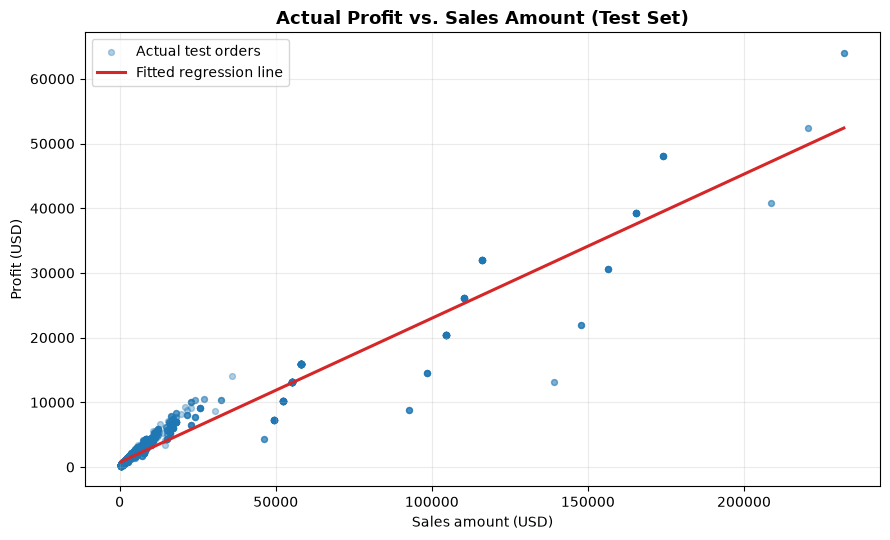

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.scatter(
    X_test["sales_amount"],
    y_test,
    alpha=0.35,
    s=18,
    color="#1f77b4",
    label="Actual test orders",
)

line_x = np.linspace(
    X_test["sales_amount"].min(),
    X_test["sales_amount"].max(),
    200,
)
line_y = model.predict(pd.DataFrame({"sales_amount": line_x}))

ax.plot(
    line_x,
    line_y,
    color="#d62728",
    linewidth=2.2,
    label="Fitted regression line",
)

ax.set_title("Actual Profit vs. Sales Amount (Test Set)", fontsize=13, fontweight="bold")
ax.set_xlabel("Sales amount (USD)")
ax.set_ylabel("Profit (USD)")
ax.legend(loc="upper left", frameon=True)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


### Interpretation of the plot

The test points cluster tightly around the fitted line, consistent with the high R². The vertical spread increases somewhat at higher sales amounts, which suggests that orders with similar sales can still have different profits because the model ignores product mix, discount levels, and cost structure.

## 8. Bottom line

The simple model is a strong descriptive fit: sales amount explains about 94% of test-set profit variation, and each extra sales dollar is associated with about 22 cents of profit in this dataset. For decision-making, use the model as a quick screening tool and add product mix, discounts, and cost drivers before treating the $10,000-order prediction as a final financial forecast.
